In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

### Load the dataset

In [2]:
X, y = load_breast_cancer(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

In [3]:
X.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [4]:
y.head(3)

0    0
1    0
2    0
Name: target, dtype: int64

#### Train a baseline model using sklearn

In [5]:
from sklearn.tree import DecisionTreeClassifier
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

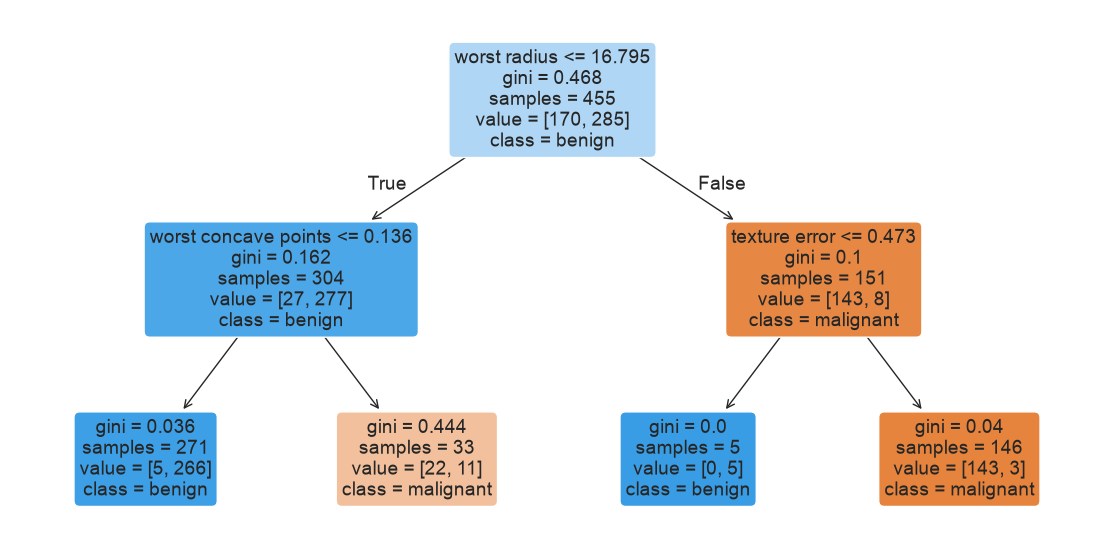

In [6]:
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 7))
plot_tree(
    tree_clf,
    feature_names=X.columns,
    class_names=["malignant", "benign"],
    filled=True,
    rounded=True,
)
plt.show()

### Train a decision tree using NumPy

##### Gini impurity function for one node

In [7]:
def gini(y):
    _,counts = np.unique(y, return_counts=True) #return an array like [50,17] (counts of each class)
    probs_squared = (counts / len(y)) ** 2
    return 1 - sum(probs_squared)

##### CART cost function

In [8]:
def cart(X, y, k, t):
    y_left = y[X[k] <= t]
    y_right = y[X[k] > t]

    # reject splits with an empty child: within that child, class
    # proportions would be 0/0. Returning infinity prevents selection.
    if len(y_left) == 0 or len(y_right) == 0: 
        return np.inf
    
    prop_l = len(y_left)/len(y) #proportion of values < t
    prop_r = len(y_right)/len(y) #proportion of values > t

    gini_l = gini(y_left)
    gini_r = gini(y_right)
    return prop_l * gini_l + prop_r * gini_r


##### Splitting algorithm

In [9]:
def find_best_split(X, y):
    best_cost = np.inf
    best_feature = None
    best_threshold = None

    for feature in X.columns:
        values = np.unique(X[feature].to_numpy())
        thresholds = (values[:-1] + values[1:]) / 2
        for t in thresholds:
            cur_cost = cart(X, y, feature, t)
            if cur_cost < best_cost:
                best_cost = cur_cost
                best_feature = feature
                best_threshold = t

    return best_feature, best_threshold, best_cost

##### Function that builds the tree

In [10]:
def build_tree(X, y, max_depth=2, depth=0):
    # Ex/
    # classes = [0, 1]
    # counts  = [2, 3]
    classes, counts = np.unique(y, return_counts=True)
    prediction = classes[np.argmax(counts)]

    if depth >= max_depth or len(classes) == 1:
        return {"prediction": prediction}

    feature, threshold, cost = find_best_split(X, y)

    if feature is None:
        return {"prediction": prediction}

    mask = X[feature] <= threshold

    return {
        "feature": feature,
        "threshold": threshold,
        "left": build_tree(
            X[mask], y[mask], max_depth, depth + 1
        ),
        "right": build_tree(
            X[~mask], y[~mask], max_depth, depth + 1
        ),
    }

##### Forward pass

In [11]:
def predict_one(tree, row):
    while "prediction" not in tree:
        feature = tree["feature"]
        threshold = tree["threshold"]

        if row[feature] <= threshold:
            tree = tree["left"]
        else:
            tree = tree["right"]

    return tree["prediction"]


def predict(tree, X):
    return np.array([
        predict_one(tree, row)
        for _, row in X.iterrows()
    ])

##### Test and compare

In [ ]:
my_tree = build_tree(X_train, y_train, max_depth=2)

my_test_pred = predict(my_tree, X_test)
sk_test_pred = tree_clf.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score

print("My tree:", accuracy_score(y_test, my_test_pred))
print("sklearn:", accuracy_score(y_test, sk_test_pred))